# 03 — Models

Train and compare models on the prepared train set from notebook 02, using the same grouped 5-fold cross-validation. The test set is only used once, at the end, on the chosen model.

## Setup

In [1]:
import sys
import time
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

from src import config

## Load the prepared data

In [2]:
train = pd.read_csv(config.PROCESSED_DIR / "train.csv")
test = pd.read_csv(config.PROCESSED_DIR / "test.csv")

PERIODS = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]

print("Train:", train.shape, " Test:", test.shape)
train["period"].value_counts().reindex(PERIODS)

Train: (288, 6)  Test: (71, 6)


period
pre-1750     38
1750-1799    47
1800-1849    56
1850-1899    71
1900-1918    76
Name: count, dtype: int64

## Cross-validation setup

Every model is scored on the same 5 folds, grouped by author, so that no author appears in both the training and validation part of a fold. Macro-F1 is the main metric; accuracy is secondary.

In [3]:
X = train["excerpt"]
y = train["period"]
groups = train["group"]

cv = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}

def evaluate(name, model):
    scores = cross_validate(model, X, y, groups=groups, cv=cv, scoring=scoring)
    return {
        "model": name,
        "macro_f1": scores["test_macro_f1"].mean(),
        "macro_f1_std": scores["test_macro_f1"].std(),
        "accuracy": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "fit_time_s": scores["fit_time"].mean(),
        "predict_time_s": scores["score_time"].mean(),
        "fold_macro_f1": scores["test_macro_f1"].round(3).tolist(),
    }

In [4]:
results = []

baseline = make_pipeline(TfidfVectorizer(), DummyClassifier(strategy="most_frequent"))
results.append(evaluate("Zero-R", baseline))

pd.DataFrame(results)

,model,macro_f1,macro_f1_std,accuracy,accuracy_std,fit_time_s,predict_time_s,fold_macro_f1
0,Zero-R,0.083507,0.001575,0.263884,0.006324,1.501803,0.377094,"[0.082, 0.086, 0.082, 0.083, 0.083]"


Making sure that we loaded the same data from notebook 2. Zero-R gives the same scores as in notebook 02 (accuracy 0.264, macro-F1 0.084), which confirms the same books and folds are being used.

## Logistic regression

Logistic regression is the simple, interpretable baseline. `C` controls regularisation: a small C keeps the word weights small (simpler model), a large C lets them grow (fits the training data more closely). Several values of C are tried on the same folds.

Only letters are kept as words, so the model can't use numbers such as years in the text to guess the period.

In [5]:
from sklearn.linear_model import LogisticRegression

def tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", min_df=10)

lr_curve = []
for C in [0.1, 1, 10, 100, 1000]:
    model = make_pipeline(tfidf(), LogisticRegression(C=C, max_iter=2000))
    row = evaluate(f"LogReg C={C}", model)
    results.append(row)
    lr_curve.append(row)

lr_table = pd.DataFrame(lr_curve)
lr_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s"]]

,model,macro_f1,macro_f1_std,accuracy,fit_time_s
0,LogReg C=0.1,0.091620,0.010027,0.267393,1.296469
1,LogReg C=1,0.363162,0.078717,0.382396,1.532282
2,LogReg C=10,0.424706,0.067745,0.424259,2.449149
3,LogReg C=100,0.459699,0.067164,0.458923,2.951035
4,LogReg C=1000,0.474141,0.060430,0.476165,2.587013


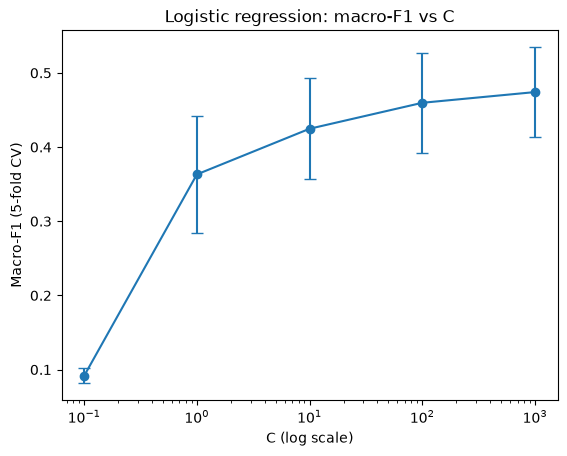

In [6]:
Cs = [0.1, 1, 10, 100, 1000]
plt.errorbar(Cs, lr_table["macro_f1"], yerr=lr_table["macro_f1_std"], marker="o", capsize=4)
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Macro-F1 (5-fold CV)")
plt.title("Logistic regression: macro-F1 vs C")
plt.show()

Logistic regression scores far above Zero-R (best macro-F1 0.474 vs 0.084), so the model is learning from the language. C=0.1 is too strongly regularised and barely beats Zero-R (0.092).
The score rises with C: C=1000 is highest (0.474 ± 0.060), but C=100 (0.460 ± 0.067) is within one standard error of it (0.060 / √5 ≈ 0.027).
Following the "one-standard-error rule", the simpler, more regularised C=100 is used from here on.
The fold spread (about ± 0.06) is large because each validation fold only has about 58 books.

### Where does logistic regression make mistakes?

Each training book gets a prediction from the fold where it was held out, and these are shown in a confusion matrix. Because the periods are in time order, it also checks how many mistakes land in a neighbouring period.

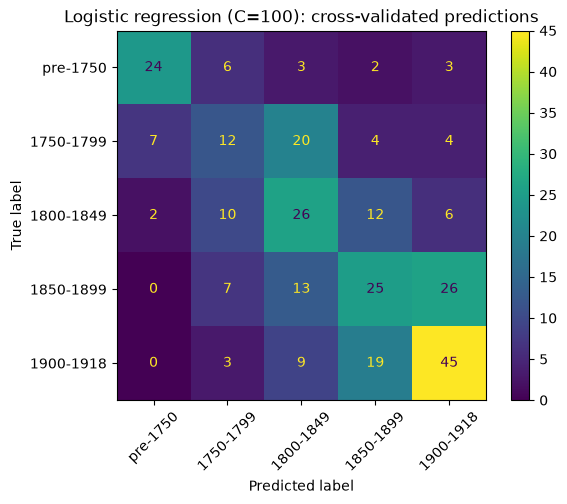

Share of mistakes in a neighbouring period: 0.724


In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

best_lr = make_pipeline(tfidf(), LogisticRegression(C=100, max_iter=2000))
lr_pred = cross_val_predict(best_lr, X, y, groups=groups, cv=cv)

ConfusionMatrixDisplay.from_predictions(y, lr_pred, labels=PERIODS, xticks_rotation=45)
plt.title("Logistic regression (C=100): cross-validated predictions")
plt.show()

def off_by_one(y_true, y_pred):
    true_i = pd.Series(y_true).map(PERIODS.index).to_numpy()
    pred_i = pd.Series(y_pred).map(PERIODS.index).to_numpy()
    wrong = true_i != pred_i
    neighbour = wrong & (abs(true_i - pred_i) == 1)
    return neighbour.sum() / wrong.sum()

print("Share of mistakes in a neighbouring period:", round(off_by_one(y, lr_pred), 3))

Row by row (true period), the share predicted correctly is: pre-1750 24/38 (63%), 1750–1799 12/47 (26%), 1800–1849 26/56 (46%), 1850–1899 25/71 (35%), 1900–1918 45/76 (59%).
The end periods (pre-1750 and 1900–1918) are recognised best, since they can only be confused in one direction.
The two weakest periods are mostly confused with a neighbour: 20 of the 47 books from 1750–1799 are predicted as 1800–1849, and 26 of the 71 books from 1850–1899 are predicted as 1900–1918 (more than are predicted correctly).
Having fewer training books does not explain this on its own: pre-1750 has even fewer (38) but is recognised best, probably because its older language is more distinctive.
Far-off mistakes are rare: no book from 1850 onwards is predicted as pre-1750.

72.4% of mistakes are in a neighbouring period. If mistakes were random this would be about 40% (8 of the 20 possible wrong pairs are neighbours), so the errors are mostly "near misses" and the model is picking up gradual change in the language.

### Which words does the model use?

The model is fitted on the full training set (not the test set) and the 10 words with the largest weights for each period are shown.

In [8]:
best_lr.fit(X, y)
vectorizer = best_lr.named_steps["tfidfvectorizer"]
lr_model = best_lr.named_steps["logisticregression"]
words = vectorizer.get_feature_names_out()

top_words = {}
for i, period in enumerate(lr_model.classes_):
    top = np.argsort(lr_model.coef_[i])[-10:][::-1]
    top_words[period] = words[top]

print("Vocabulary size:", len(words))
pd.DataFrame(top_words)[PERIODS]

Vocabulary size: 7123


,pre-1750,1750-1799,1800-1849,1850-1899,1900-1918
0,be,smith,mamma,harry,mr
1,that,this,his,richard,duke
2,princess,ma,sir,said,he
3,de,governor,emperor,john,the
4,ship,to,philip,sheep,german
5,this,which,society,flame,ve
6,circle,your,was,there,seemed
7,madame,upon,we,monk,crow
8,which,continent,fable,dollars,had
9,hath,my,which,as,for


On the first version of the dataset (446 books), the top words with min_df=2 included many character names (e.g. sancho, yorick, jules), so the model was memorising individual books.
Raising min_df to 10 (a word must appear in at least 10 books) gave the same macro-F1 (0.455 vs 0.453) with a smaller fold spread, and the top words became period language and topics.
Names do not inflate the score, because the split is grouped by author, but they make the model harder to interpret. min_df=10 is used for every model.

On the cleaned data (C=100), the top words are a mix of:
- Period language: *hath* and frequent use of *which*, *that* and *be* for pre-1750; *ve* (from contractions such as "I've") for 1900–1918.
- Topics of the time: *governor* and *continent* (the American colonies) for 1750–1799; *emperor* (Napoleon) and *society* for 1800–1849; *dollars* for 1850–1899; *german* (the First World War) for 1900–1918.
- Some remaining names and words tied to a few books: *princess*, *madame* and *de* for pre-1750 (likely from French-themed books such as *The Princess of Montpensier*, a translation not caught in notebook 02), *harry*, *richard* and *john* for 1850–1899.

So the model partly uses topic rather than language style, which may not carry over to books on other subjects.

## k-nearest neighbours (kNN)

kNN predicts a book's period by finding the k most similar training books and taking a vote. Similarity is measured with cosine distance, which compares which words are used rather than how long the text is. Several values of k are tried on the same folds.

In [9]:
from sklearn.neighbors import KNeighborsClassifier

ks = [1, 3, 5, 10, 15, 25, 40]
knn_curve = []
for k in ks:
    model = make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=k, metric="cosine"))
    row = evaluate(f"kNN k={k}", model)
    results.append(row)
    knn_curve.append(row)
    print("k =", k, "done")

knn_table = pd.DataFrame(knn_curve)
knn_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s", "predict_time_s"]]

k = 1 done
k = 3 done
k = 5 done
k = 10 done
k = 15 done
k = 25 done
k = 40 done


,model,macro_f1,macro_f1_std,accuracy,fit_time_s,predict_time_s
0,kNN k=1,0.301121,0.057443,0.302299,1.252157,0.336445
1,kNN k=3,0.270978,0.059076,0.288143,1.277520,0.328593
2,kNN k=5,0.345210,0.055150,0.350877,1.306142,0.340206
3,kNN k=10,0.278080,0.040854,0.308711,1.172841,0.312425
4,kNN k=15,0.323699,0.045769,0.350756,1.173782,0.329320
5,kNN k=25,0.286766,0.042532,0.330006,1.139049,0.301247
6,kNN k=40,0.271698,0.018169,0.326497,1.116394,0.319456


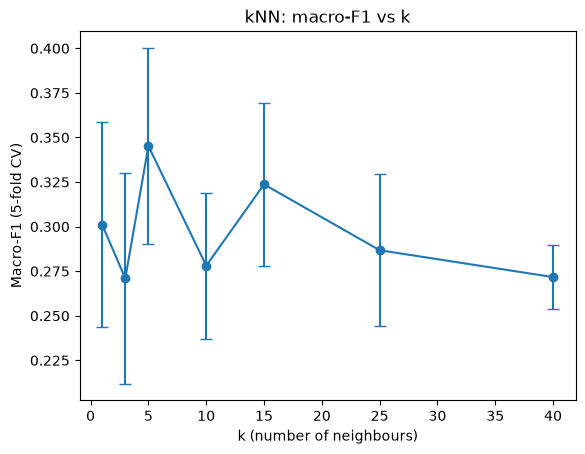

In [10]:
plt.errorbar(ks, knn_table["macro_f1"], yerr=knn_table["macro_f1_std"], marker="o", capsize=4)
plt.xlabel("k (number of neighbours)")
plt.ylabel("Macro-F1 (5-fold CV)")
plt.title("kNN: macro-F1 vs k")
plt.show()

kNN is highest at k=5 (macro-F1 0.345 ± 0.055), well above Zero-R (0.084) but below logistic regression (0.460).
The score jumps up and down with k (k=1: 0.301, k=3: 0.271, k=5: 0.345, k=10: 0.278) and the error bars overlap, so no k is clearly best.
A larger k is a simpler (smoother) model, and k=15 (0.324) is within one standard error of the best (0.055 / √5 ≈ 0.025), so k=15 is used below.
kNN is likely weaker than logistic regression because it treats every word as equally important, so books can look similar because they share a topic rather than a period, while logistic regression learns which words matter.
kNN does no real training (fit time is mostly TF-IDF); the work happens at prediction time.

## Decision tree

A decision tree asks a series of yes/no questions about word weights (e.g. "is 'hath' above 0.01?") to reach a period. `max_depth` limits how many questions it can ask: a shallow tree is simple, a deep tree can memorise the training books. Several depths are tried on the same folds.

In [11]:
from sklearn.tree import DecisionTreeClassifier

depths = [2, 4, 6, 10, 15, 25, None]
tree_curve = []
for d in depths:
    model = make_pipeline(tfidf(), DecisionTreeClassifier(max_depth=d, random_state=config.RANDOM_STATE))
    row = evaluate(f"Tree depth={d}", model)
    results.append(row)
    tree_curve.append(row)
    print("depth =", d, "done")

tree_table = pd.DataFrame(tree_curve)
tree_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s", "predict_time_s"]]

depth = 2 done
depth = 4 done
depth = 6 done
depth = 10 done
depth = 15 done
depth = 25 done
depth = None done


,model,macro_f1,macro_f1_std,accuracy,fit_time_s,predict_time_s
0,Tree depth=2,0.249131,0.021990,0.312583,1.243252,0.279344
1,Tree depth=4,0.305852,0.036208,0.322989,1.391798,0.296440
2,Tree depth=6,0.340666,0.037775,0.347308,1.504313,0.289034
3,Tree depth=10,0.336635,0.045543,0.340230,1.565330,0.316345
4,Tree depth=15,0.318542,0.058944,0.322626,1.619234,0.310631
5,Tree depth=25,0.318542,0.058944,0.322626,1.589888,0.297029
6,Tree depth=None,0.318542,0.058944,0.322626,1.589468,0.288103


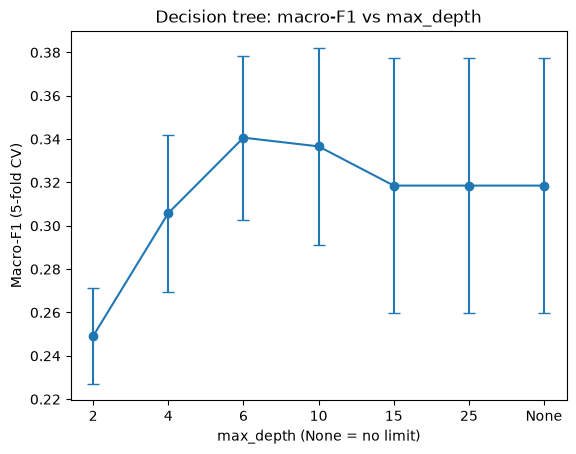

In [12]:
depth_labels = [str(d) for d in depths]
plt.errorbar(depth_labels, tree_table["macro_f1"], yerr=tree_table["macro_f1_std"], marker="o", capsize=4)
plt.xlabel("max_depth (None = no limit)")
plt.ylabel("Macro-F1 (5-fold CV)")
plt.title("Decision tree: macro-F1 vs max_depth")
plt.show()

The decision tree is best at max_depth=6 (macro-F1 0.341 ± 0.038), with depth 10 close behind (0.337). It is above Zero-R (0.084), similar to kNN, and below logistic regression (0.460).
Depth 2 underfits (0.249). Deeper trees score lower (0.319 at depth 15), a sign of overfitting: they memorise the training books.
Depth 15, 25 and no limit give identical results, so the tree stops growing before depth 15.
Depth 4 (0.306) is not within one standard error of the best (0.038 / √5 ≈ 0.017), so depth 6 is used below.
Trees are likely weak here because each split uses a single word, while the period signal is spread across many small differences in word use, which logistic regression combines all at once.

### Where do the models disagree?

Each model's cross-validated predictions are compared book by book, to see whether the models make the same mistakes or different ones.

In [13]:
best_knn = make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=15, metric="cosine"))
best_tree = make_pipeline(tfidf(), DecisionTreeClassifier(max_depth=6, random_state=config.RANDOM_STATE))

knn_pred = cross_val_predict(best_knn, X, y, groups=groups, cv=cv)
tree_pred = cross_val_predict(best_tree, X, y, groups=groups, cv=cv)

compare = pd.DataFrame({
    "title": train["title"],
    "true": y,
    "lr": lr_pred,
    "knn": knn_pred,
    "tree": tree_pred,
})
compare["lr_right"] = compare["lr"] == compare["true"]
compare["knn_right"] = compare["knn"] == compare["true"]
compare["tree_right"] = compare["tree"] == compare["true"]

print("All three right:", (compare.lr_right & compare.knn_right & compare.tree_right).sum())
print("All three wrong:", (~compare.lr_right & ~compare.knn_right & ~compare.tree_right).sum())
print("Only LR right:  ", (compare.lr_right & ~compare.knn_right & ~compare.tree_right).sum())
print("LR wrong, another model right:", (~compare.lr_right & (compare.knn_right | compare.tree_right)).sum())

compare[~compare.lr_right & ~compare.knn_right & ~compare.tree_right][["title", "true", "lr", "knn", "tree"]].head(10)

All three right: 32
All three wrong: 86
Only LR right:   41
LR wrong, another model right: 70


,title,true,lr,knn,tree
0,A Short View of the Immorality and Profaneness...,pre-1750,1750-1799,1800-1849,1850-1899
1,The Princess of Montpensier by Madame de La Fa...,pre-1750,1900-1918,1850-1899,1850-1899
3,The Path-Way to Knowledg by Robert Record,pre-1750,1850-1899,1800-1849,1900-1918
20,The Friendly Daemon or the Generous Apparition...,pre-1750,1750-1799,1750-1799,1750-1799
21,From This World to the Next by Henry Fielding,pre-1750,1800-1849,1800-1849,1850-1899
22,The King of Pirates by Daniel Defoe,pre-1750,1800-1849,1800-1849,1850-1899
24,A New Voyage to Carolina by John Lawson,pre-1750,1900-1918,1800-1849,1850-1899
26,The Works of Samuel Johnson LL.D. in Nine Volu...,pre-1750,1750-1799,1750-1799,1800-1849
30,A Short Discourse Concerning Pestilential Cont...,pre-1750,1750-1799,1750-1799,1750-1799
33,Essays on Mankind and Political Arithmetic by ...,pre-1750,1900-1918,1750-1799,1750-1799


86 of 288 books (30%) are wrong for all three models, and 32 are right for all three.
For 70 of the 156 books that logistic regression gets wrong (45%), kNN or the tree gets them right, so the models make quite different mistakes. This suggests combining many models (random forest, boosting) may help.

The table shows the first 10 books that all three models get wrong (they are all pre-1750, because the table is in period order). Most are predicted as a later period, often 1750–1799 (a neighbour).
A few may still have label or text problems: *The Princess of Montpensier* is a translation not caught by the title-page check, and *The Works of Samuel Johnson* is labelled pre-1750 although most of Johnson's work is from after 1750.
These are not removed, for the reason given in notebook 02: removing books only because the models got them wrong would make the scores look better than they really are.

**First run (before the title-page check in notebook 02):** 123 of 357 books were wrong for all three models. Looking at these showed label problems rather than model problems:
- Titles labelled incorrectly: *The Submarine Boys for the Flag* was published c. 1910, not before 1750. It is labelled 1705 in PG-19 itself, and slipped through the year check because its excerpt mentions no years (the 1910 is on the title page).
- Translations published at a later date, so their language is more modern than the label, e.g. *Don Quixote* (labelled 1615) is in a 19th-century English translation.
- Books dated close to the end of a period, e.g. Hume's *Treatise* (1739–40) and *Clarissa* (1748), predicted as 1750–1799.

This led to the title-page check in notebook 02, which removes later-dated books and translations from every book before the split. All results in this notebook are from the cleaned data.

## Random forest

A random forest trains many decision trees, each on a random sample of the books and a random subset of words, and takes a vote. This averages out the mistakes of single trees, which overfit easily. The number of trees is varied on the same folds.

In [14]:
from sklearn.ensemble import RandomForestClassifier

n_trees = [50, 100, 300, 500]
rf_curve = []
for n in n_trees:
    model = make_pipeline(tfidf(), RandomForestClassifier(n_estimators=n, random_state=config.RANDOM_STATE, n_jobs=-1))
    row = evaluate(f"Forest trees={n}", model)
    results.append(row)
    rf_curve.append(row)
    print("trees =", n, "done")

rf_table = pd.DataFrame(rf_curve)
rf_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s", "predict_time_s"]]

trees = 50 done
trees = 100 done
trees = 300 done
trees = 500 done


,model,macro_f1,macro_f1_std,accuracy,fit_time_s,predict_time_s
0,Forest trees=50,0.428452,0.080107,0.437810,1.570978,0.357464
1,Forest trees=100,0.498346,0.072906,0.490139,1.685744,0.366587
2,Forest trees=300,0.485505,0.074594,0.486691,2.805478,0.475708
3,Forest trees=500,0.506249,0.081544,0.507623,3.460936,0.572579


The random forest reaches macro-F1 0.506 ± 0.082 with 500 trees, the best score so far, ahead of logistic regression (0.460). The score levels off after about 100 trees (0.498 at 100, 0.486 at 300, 0.506 at 500): more trees make the vote more stable but stop improving it. Using the one-standard-error rule (0.082 / √5 ≈ 0.037), 100 trees is within range of the best and is the cheapest, so 100 trees is used for the comparison. The forest beats a single tree (0.341) because averaging many trees, each trained on different books and words, cancels out their individual mistakes.

## Gradient Boosting
Boosting also uses many small trees, but builds them one after another: each new tree focuses on the books the previous trees got wrong. The number of boosting rounds is varied on the same folds. Each tree only looks at a random subset of words (max_features="sqrt") to keep training time reasonable with about 7,000 words.

In [15]:
from sklearn.ensemble import GradientBoostingClassifier

n_rounds = [50, 100, 200, 400]
gb_curve = []
for n in n_rounds:
    model = make_pipeline(tfidf(), GradientBoostingClassifier(
        n_estimators=n, learning_rate=0.1, max_depth=3,
        max_features="sqrt", random_state=config.RANDOM_STATE))
    row = evaluate(f"Boosting rounds={n}", model)
    results.append(row)
    gb_curve.append(row)
    print("rounds =", n, "done")

gb_table = pd.DataFrame(gb_curve)
gb_table[["model", "macro_f1", "macro_f1_std", "accuracy", "fit_time_s", "predict_time_s"]]

rounds = 50 done
rounds = 100 done
rounds = 200 done
rounds = 400 done


,model,macro_f1,macro_f1_std,accuracy,fit_time_s,predict_time_s
0,Boosting rounds=50,0.405810,0.082289,0.431216,2.327597,0.303796
1,Boosting rounds=100,0.438619,0.081745,0.444949,3.405810,0.292000
2,Boosting rounds=200,0.470360,0.073688,0.465759,5.547004,0.301724
3,Boosting rounds=400,0.505606,0.063637,0.496975,9.818003,0.287555


Gradient boosting reaches macro-F1 0.506 ± 0.064 with 400 rounds, almost the same as the random forest, and is still improving at 400 rounds, so more rounds might help further. It is the slowest model to train (about 3 times slower than a 500-tree forest), because its trees are built one after another rather than independently.

## Comparing Models

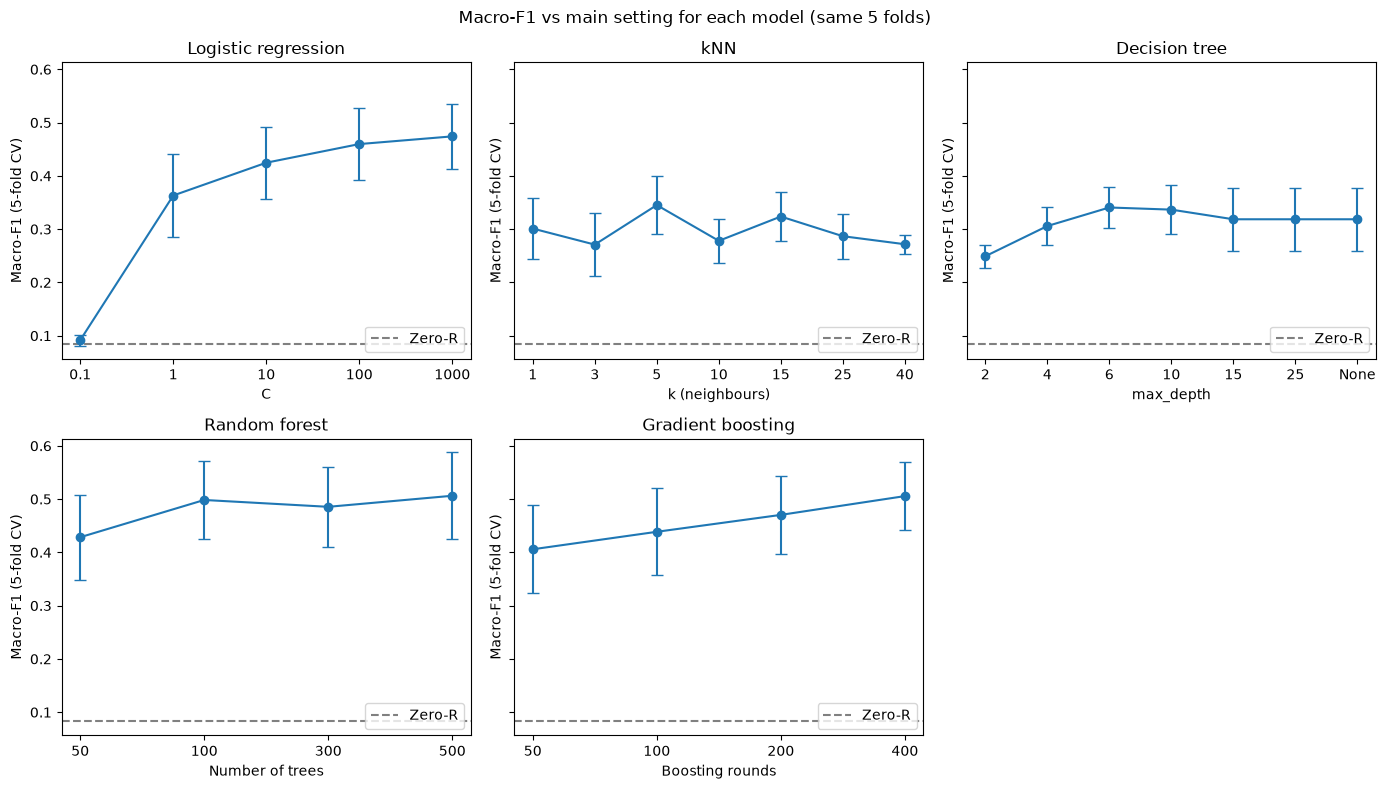

In [16]:
zero_r = results[0]["macro_f1"]

curves = [
    ("Logistic regression", [str(c) for c in Cs], lr_table, "C"),
    ("kNN", [str(k) for k in ks], knn_table, "k (neighbours)"),
    ("Decision tree", depth_labels, tree_table, "max_depth"),
    ("Random forest", [str(n) for n in n_trees], rf_table, "Number of trees"),
    ("Gradient boosting", [str(n) for n in n_rounds], gb_table, "Boosting rounds"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
axes = axes.flatten()

for ax, (title, x, table, xlabel) in zip(axes, curves):
    ax.errorbar(x, table["macro_f1"], yerr=table["macro_f1_std"], marker="o", capsize=4)
    ax.axhline(zero_r, linestyle="--", color="grey", label="Zero-R")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Macro-F1 (5-fold CV)")
    ax.legend(loc="lower right")

axes[-1].axis("off")
plt.suptitle("Macro-F1 vs main setting for each model (same 5 folds)")
plt.tight_layout()
plt.show()

All five models are well above Zero-R (dashed line), except logistic regression with C=0.1. The panels share the same y-axis, so heights can be compared directly. kNN and the decision tree stay around 0.3 whatever their setting, while logistic regression, the random forest and gradient boosting reach about 0.46–0.51. The error bars of these three overlap heavily, so they cannot be clearly separated yet; this is checked fold by fold in the comparison below. Gradient boosting is still rising at 400 rounds, while the forest may level off after about 100 trees. The x-axis shows each setting evenly spaced, not to scale.

### Comparison table

The chosen setting of each model (from the tuning above) is compared on the same 5 folds: macro-F1 (main metric), accuracy, and the average time to train and predict per fold.

In [17]:
chosen = ["Zero-R", "LogReg C=100", "kNN k=15", "Tree depth=6", "Forest trees=100", "Boosting rounds=400"]

summary = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model").loc[chosen]
summary[["macro_f1", "macro_f1_std", "accuracy", "accuracy_std", "fit_time_s", "predict_time_s"]].round(3)

,macro_f1,macro_f1_std,accuracy,accuracy_std,fit_time_s,predict_time_s
model,,,,,,
Zero-R,0.084,0.002,0.264,0.006,1.502,0.377
LogReg C=100,0.460,0.067,0.459,0.076,2.951,0.270
kNN k=15,0.324,0.046,0.351,0.021,1.174,0.329
Tree depth=6,0.341,0.038,0.347,0.053,1.504,0.289
Forest trees=100,0.498,0.073,0.490,0.084,1.686,0.367
Boosting rounds=400,0.506,0.064,0.497,0.068,9.818,0.288


Gradient boosting (macro-F1 0.506 ± 0.064) and the random forest (0.498 ± 0.073) score highest, followed by logistic regression (0.460 ± 0.067). kNN (0.324) and the decision tree (0.341) are clearly weaker. All models train and predict in seconds because the dataset is small. Boosting is the slowest to train (about 3–6 times slower than the other models) because its trees are built one after another. Exact times depend on the computer and vary between runs, so only the comparison between models is meaningful.

### Fold-by-fold comparison

All models use the same 5 folds, so they can be compared on each fold separately. If a model beats logistic regression on most folds, the difference is more convincing than the averages alone.

,fold 1,fold 2,fold 3,fold 4,fold 5,beats LR in
model,,,,,,
Zero-R,0.082,0.086,0.082,0.083,0.083,0
LogReg C=100,0.412,0.378,0.440,0.567,0.502,0
kNN k=15,0.324,0.298,0.308,0.278,0.410,0
Tree depth=6,0.384,0.330,0.280,0.332,0.378,0
Forest trees=100,0.506,0.434,0.416,0.513,0.623,3
Boosting rounds=400,0.482,0.433,0.493,0.495,0.625,4


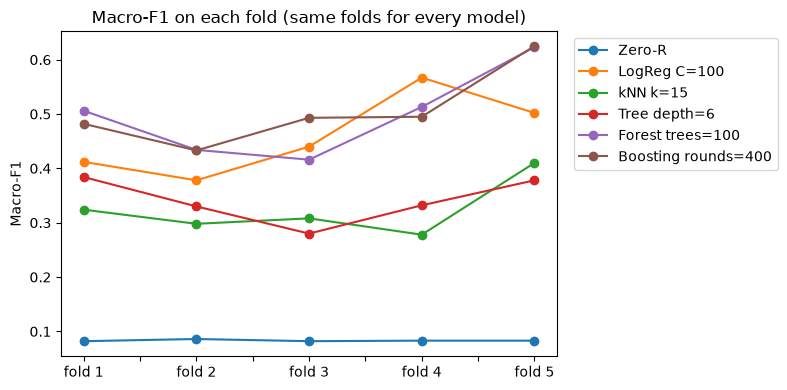

In [18]:
folds = pd.DataFrame(summary["fold_macro_f1"].tolist(), index=summary.index,
                     columns=[f"fold {i + 1}" for i in range(config.CV_FOLDS)])

folds["beats LR in"] = (folds.iloc[:, :config.CV_FOLDS].gt(folds.loc["LogReg C=100"].iloc[:config.CV_FOLDS], axis=1)).sum(axis=1)
display(folds)

folds.iloc[:, :config.CV_FOLDS].T.plot(marker="o", figsize=(8, 4))
plt.ylabel("Macro-F1")
plt.title("Macro-F1 on each fold (same folds for every model)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Boosting beats logistic regression on 4 of 5 folds (on average 0.046 higher per fold), and the random forest beats logistic regression on 3 of 5 (0.039 higher).
The folds differ in difficulty: fold 5 is the easiest for most models, but the models do not always rise and fall together (e.g. fold 4 is logistic regression's best fold but kNN's worst). Comparing on the same fold removes the effect of which books happen to be in each fold.
The advantage of boosting is consistent but small, and with only 5 folds it is not strong proof.

### Model complexity

Each chosen model is trained once on the full training set to measure how big it is and how long training takes. Size is measured as the number of learned weights (logistic regression), stored values (kNN, which keeps every training book) or tree nodes (tree, forest, boosting).

In [19]:
final_models = {
    "LogReg C=100": make_pipeline(tfidf(), LogisticRegression(C=100, max_iter=2000)),
    "kNN k=15": make_pipeline(tfidf(), KNeighborsClassifier(n_neighbors=15, metric="cosine")),
    "Tree depth=6": make_pipeline(tfidf(), DecisionTreeClassifier(max_depth=6, random_state=config.RANDOM_STATE)),
    "Forest trees=100": make_pipeline(tfidf(), RandomForestClassifier(n_estimators=100, random_state=config.RANDOM_STATE, n_jobs=-1)),
    "Boosting rounds=400": make_pipeline(tfidf(), GradientBoostingClassifier(
        n_estimators=400, learning_rate=0.1, max_depth=3, max_features="sqrt", random_state=config.RANDOM_STATE)),
}

def model_size(model):
    m = model[-1]
    if isinstance(m, LogisticRegression):
        return m.coef_.size, "weights"
    if isinstance(m, KNeighborsClassifier):
        return m.n_samples_fit_ * m.n_features_in_, "stored values"
    if isinstance(m, DecisionTreeClassifier):
        return m.tree_.node_count, "tree nodes"
    if isinstance(m, RandomForestClassifier):
        return sum(t.tree_.node_count for t in m.estimators_), "tree nodes"
    return sum(t.tree_.node_count for t in m.estimators_.ravel()), "tree nodes"

rows = []
for name, model in final_models.items():
    start = time.time()
    model.fit(X, y)
    fit_s = time.time() - start
    size, unit = model_size(model)
    rows.append({"model": name, "train_time_s": round(fit_s, 2), "size": size, "unit": unit})

pd.DataFrame(rows).set_index("model")

,train_time_s,size,unit
model,,,
LogReg C=100,3.68,35615,weights
kNN k=15,1.47,2051424,stored values
Tree depth=6,2.09,63,tree nodes
Forest trees=100,2.10,12442,tree nodes
Boosting rounds=400,11.10,27838,tree nodes


The single tree is the smallest (63 nodes) and easiest to explain, but weak. Logistic regression has 35,615 weights (7,123 words × 5 periods), each of which can be read directly, which is how the top words were found. The random forest (12,442 nodes) and boosting (27,838 nodes across 2,000 small trees) are much harder to explain. kNN stores every training book (about 2 million values), so it grows with the data. Training times include building the TF-IDF vocabulary.

## Preferred model

Gradient boosting with 400 rounds is chosen as the preferred model, based on cross-validation only (the test set has not been used yet):
- highest mean macro-F1 (0.506 ± 0.064) and smallest spread of the top three models;
- beats logistic regression on 4 of 5 folds;
- the cost is a longer training time (the slowest model, though still only seconds) and a model that is harder to explain than logistic regression.

Logistic regression (0.460) is kept as the interpretable comparison, since its word weights show what the models are picking up.

## Final test

Test-set rule: the 71 test books are used once, only for the chosen model, after all tuning and model choice are finished. The model is trained on all 288 training books and scored on the test set. The result is reported as it is, and nothing is changed afterwards because of it.

Test macro-F1: 0.519   (cross-validation: 0.506 ± 0.064)
Test accuracy: 0.507   (cross-validation: 0.497)
Share of mistakes in a neighbouring period: 0.8

              precision    recall  f1-score   support

    pre-1750       0.70      0.70      0.70        10
   1750-1799       0.71      0.45      0.56        11
   1800-1849       0.50      0.36      0.42        14
   1850-1899       0.32      0.35      0.33        17
   1900-1918       0.52      0.68      0.59        19

    accuracy                           0.51        71
   macro avg       0.55      0.51      0.52        71
weighted avg       0.52      0.51      0.50        71



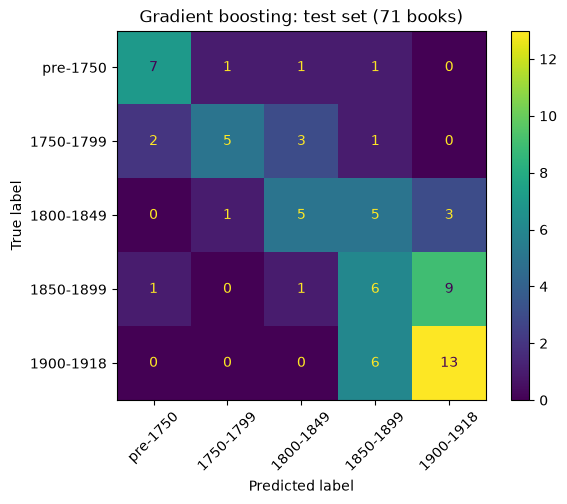

In [20]:
from sklearn.metrics import f1_score, accuracy_score, classification_report

final_model = final_models["Boosting rounds=400"]
test_pred = final_model.predict(test["excerpt"])

test_f1 = f1_score(test["period"], test_pred, average="macro")
test_acc = accuracy_score(test["period"], test_pred)

print(f"Test macro-F1: {test_f1:.3f}   (cross-validation: {summary.loc['Boosting rounds=400', 'macro_f1']:.3f} ± {summary.loc['Boosting rounds=400', 'macro_f1_std']:.3f})")
print(f"Test accuracy: {test_acc:.3f}   (cross-validation: {summary.loc['Boosting rounds=400', 'accuracy']:.3f})")
print("Share of mistakes in a neighbouring period:", round(off_by_one(test["period"], test_pred), 3))
print()
print(classification_report(test["period"], test_pred, labels=PERIODS, zero_division=0))

ConfusionMatrixDisplay.from_predictions(test["period"], test_pred, labels=PERIODS, xticks_rotation=45)
plt.title("Gradient boosting: test set (71 books)")
plt.show()

On the 71 unseen test books, gradient boosting scores macro-F1 0.519 and accuracy 0.507, close to its cross-validation estimate (0.506 ± 0.064). This suggests the cross-validation estimate was fair and the tuning did not overfit the training folds. It is far above Zero-R (0.084 macro-F1) and random guessing (about 0.20 accuracy).

80% of the mistakes (28 of 35) are in a neighbouring period, so most errors are near misses. pre-1750 is recognised best (F1 0.70) and 1850–1899 worst (F1 0.33): 9 of its 17 books are predicted as 1900–1918, the same confusion seen in cross-validation, which suggests late-Victorian and early-20th-century English are hard to separate with word counts alone. The test set is small (10–19 books per period), so the per-period scores are uncertain: one book changes a period's score by 5–10 points.

## Save the results

Every cross-validation run in this notebook (including fold scores and timings) is saved for the experiment log in `reports/experiment_log.md`.

In [21]:
log = pd.DataFrame(results).drop_duplicates("model", keep="last")
log.to_csv(config.ROOT / "reports" / "experiment_results.csv", index=False)
print("Saved", len(log), "runs")

Saved 28 runs
